# Saltiness enhancement: assay conditions, dose and transfer

Ratchanon Preecha · 15 October 2026

**Research question:** do peptide-level labels and rankings remain useful when we inspect actual NaCl-enhancement experiments and dose curves?

This follow-up curates **11 synthesized candidates from two complete published panels**, **18 dose-response means from three peptides**, and checks a concrete benchmark-label conflict. It fits only four previously fixed baselines. Experimental findings belong to the cited authors; this is a retrospective reproducible analysis, not a new-molecule discovery or blind external validation.

**CPU is sufficient.** No docking, GPU, upload or API key is needed. Fresh installation may take about 2–5 minutes depending on downloads; analysis itself takes seconds. Full primary-source links, attribution and caveats are embedded in README.md and SOURCE_MANIFEST.json.

Read the outputs in order: (1) original negative label versus enhancement evidence, (2) dose-dependent ranking, (3) held-out panel retrieval, (4) source inconsistencies and the resulting research decision.

In [1]:
from pathlib import Path
import os,sys,subprocess,shutil,hashlib,json,base64,io,zipfile,csv,html,time
from IPython.display import display,HTML,Image,FileLink
os.environ['MPLBACKEND']='Agg'
BASE=Path('/content/salt_assay_conditions') if Path('/content').is_dir() else Path.cwd()/'salt_assay_conditions'
WORK=BASE/'work';WORK.mkdir(parents=True,exist_ok=True)
PAYLOAD_SHA256='358a7ae01eb6f867dd33d0e6eb62af8ad30ba8001fda461052c7256dff8aeeb3'
EMBEDDED_INPUTS='...'
raw=base64.b64decode(EMBEDDED_INPUTS)
assert hashlib.sha256(raw).hexdigest()==PAYLOAD_SHA256
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    for name in z.namelist():
        path=(WORK/name).resolve()
        if not path.is_relative_to(WORK.resolve()):raise ValueError('Unexpected input path')
        path.parent.mkdir(parents=True,exist_ok=True);path.write_bytes(z.read(name))
LOGS=BASE/'logs';LOGS.mkdir(exist_ok=True)
print('Verified embedded input package:',PAYLOAD_SHA256)
print('Readable code and source workbook:',WORK)


Verified embedded input package: 358a7ae01eb6f867dd33d0e6eb62af8ad30ba8001fda461052c7256dff8aeeb3
Readable code and source workbook: /workspace/scratch/cadb742a5030/research/assay_conditions_20261015/notebook_validation/salt_assay_conditions/work


## Isolated Python 3.12 environment

The notebook kernel only orchestrates the scientific worker. Pinned binary dependencies and `MPLBACKEND=Agg` avoid the earlier Vina-build and inherited-inline-backend problems. This reuses the preceding setup and adds RDKit for the chemical mass calculations.

In [2]:
def command(args,name,timeout=900):
    env=os.environ.copy();env.update(MPLBACKEND='Agg',OMP_NUM_THREADS='2',OPENBLAS_NUM_THREADS='2')
    path=LOGS/(name+'.log');start=time.monotonic()
    print('Running:',name,flush=True)
    with path.open('w') as out:
        result=subprocess.run([str(a) for a in args],cwd=WORK,env=env,stdout=out,stderr=subprocess.STDOUT,timeout=timeout)
    if result.returncode:
        print(path.read_text(errors='replace')[-5000:]);raise RuntimeError('Failed: '+name+'; log: '+str(path))
    print(name,':',round(time.monotonic()-start,1),'seconds',flush=True)

uv=shutil.which('uv')
if uv is None or subprocess.check_output([uv,'--version'],text=True).split()[1]!='0.12.23':
    bootstrap=BASE/'bootstrap'
    command([sys.executable,'-m','pip','install','--quiet','--upgrade','--only-binary=:all:','--target',bootstrap,'uv==0.12.23'],'bootstrap_uv')
    uv=str(bootstrap/'bin/uv')
PY=BASE/'python312/bin/python'
if not PY.exists():command([uv,'venv','--python','3.12',PY.parent.parent],'create_python312')
command([uv,'pip','install','--python',PY,'--only-binary',':all:','-r',WORK/'requirements_locked.txt'],'install_locked_packages')
command([uv,'pip','check','--python',PY],'check_dependencies')
expected=dict(line.split('==') for line in (WORK/'requirements_locked.txt').read_text().splitlines() if '==' in line and not line.startswith('#'))
query='import sys,json,importlib.metadata as m;print(json.dumps({"python":list(sys.version_info[:3]),"packages":{n:m.version(n) for n in '+repr(list(expected))+'}}))'
actual=json.loads(subprocess.check_output([str(PY),'-c',query],text=True))
assert actual['python'][:2]==[3,12] and actual['packages']==expected
(WORK/'worker_environment.json').write_text(json.dumps(actual,indent=2))
print('Verified Python',actual['python'],'and',len(expected),'locked packages.')


Running: install_locked_packages
install_locked_packages : 0.0 seconds
Running: check_dependencies
check_dependencies : 0.0 seconds
Verified Python [3, 12, 14] and 20 locked packages.


## Run the defined analysis

The protocol is **post-hoc to paper selection and observed source issues**; model definitions were fixed previously. We exclude exact matches, full sequence-similarity components and known test-source citations before training. No tuning or AUC on unresolved negatives. Each model is fitted once; all predictions and exclusions are exported.

In [3]:
print((WORK/'PROTOCOL.md').read_text())
command([PY,WORK/'analyse_conditions.py'],'condition_analysis')
RESULTS=WORK/'results'
def table(name):
    with (RESULTS/name).open(newline='') as f:
        rows=list(csv.reader(f))
    display(HTML('<div style="overflow:auto"><table>'+''.join('<tr>'+''.join('<'+('th' if i==0 else 'td')+' style="padding:5px;border:1px solid #ddd">'+html.escape(v)+'</'+('th' if i==0 else 'td')+'>' for v in row)+'</tr>' for i,row in enumerate(rows))+'</table></div>'))
print('Original benchmark record (not globally relabelled):')
table('NGYDMR_original_benchmark_record.csv')
print('Compare with the condition-specific evidence in work/data/fixed_assay_panels.csv.')
print((RESULTS/'run_receipt.json').read_text())

# Condition-aware follow-up, 15 October 2026

This is a **post-hoc follow-up** to the source-transfer experiment. The papers,
their outcomes, the NGYDMR discrepancy and the dose curves were inspected before
this protocol. The four model definitions were fixed in the preceding experiment;
no claim of prospective discovery or a blind external benchmark is made.

## Questions and stopping rules

1. Can the earlier fixed sequence baselines retrieve reported NaCl enhancers in
   two complete, author-selected synthesis panels? Fit each of the same four
   models once, seed 777, on the sensory-tagged benchmark subset. Remove exact
   matches, entire >=0.8 normalized-Levenshtein connected components touching
   either panel, and records citing the panel papers or NGYDMR's older source.
   Export all exclusions and all scores. Report known-positive retrieval among
   the top three per panel. Do not select a winner, tune, calculate a pooled AUC,
   or interpret scores as calibrated probabilities

sequence,label,source_sheet,source_row,evidence,phenotype,assay_context,material,references,doi_tokens,sensory_tagged,explicit_enhancement_wording,sodium_salt_mention,nacl_context_mention,ph_context_mention
NGYDMR,0,Table S2_Negative,246,B1 - excluded as salty in the same sensory study,"umami, sweetness",synthetic peptide; trained human sensory panel; direct descriptive sensory evaluation; no salty descriptor; 1 mg/mL; taste threshold 0.17 mmol/L; relaxed negative criterion,,10.1016/j.foodchem.2025.145575,10.1016/j.foodchem.2025.145575,True,False,False,False,False


## Published dose curves and ranking reversal

Table S4 of [Foods 2024, 13, 995](https://doi.org/10.3390/foods13070995), nominal NaCl 0.5 g/L. Error bars are the **published SD**, not a confidence interval we calculated. Dose zero is shared control context, not three independent peptide findings. No new p-values or EC50s are estimated.

**Source limitations:** Methods 2.11 leaves stock/final concentrations ambiguous after 1:1 mixing. Figure 8 shows VP10's last value around 9 but Table S4 gives 8.0; this notebook uses Table S4. Both versions preserve the ranking reversal. Keep these concerns attached to every formulation interpretation.

Fixed-model retrieval of reported significant enhancers; random expectation is descriptive:
Scores are not calibrated probabilities of NaCl enhancement.


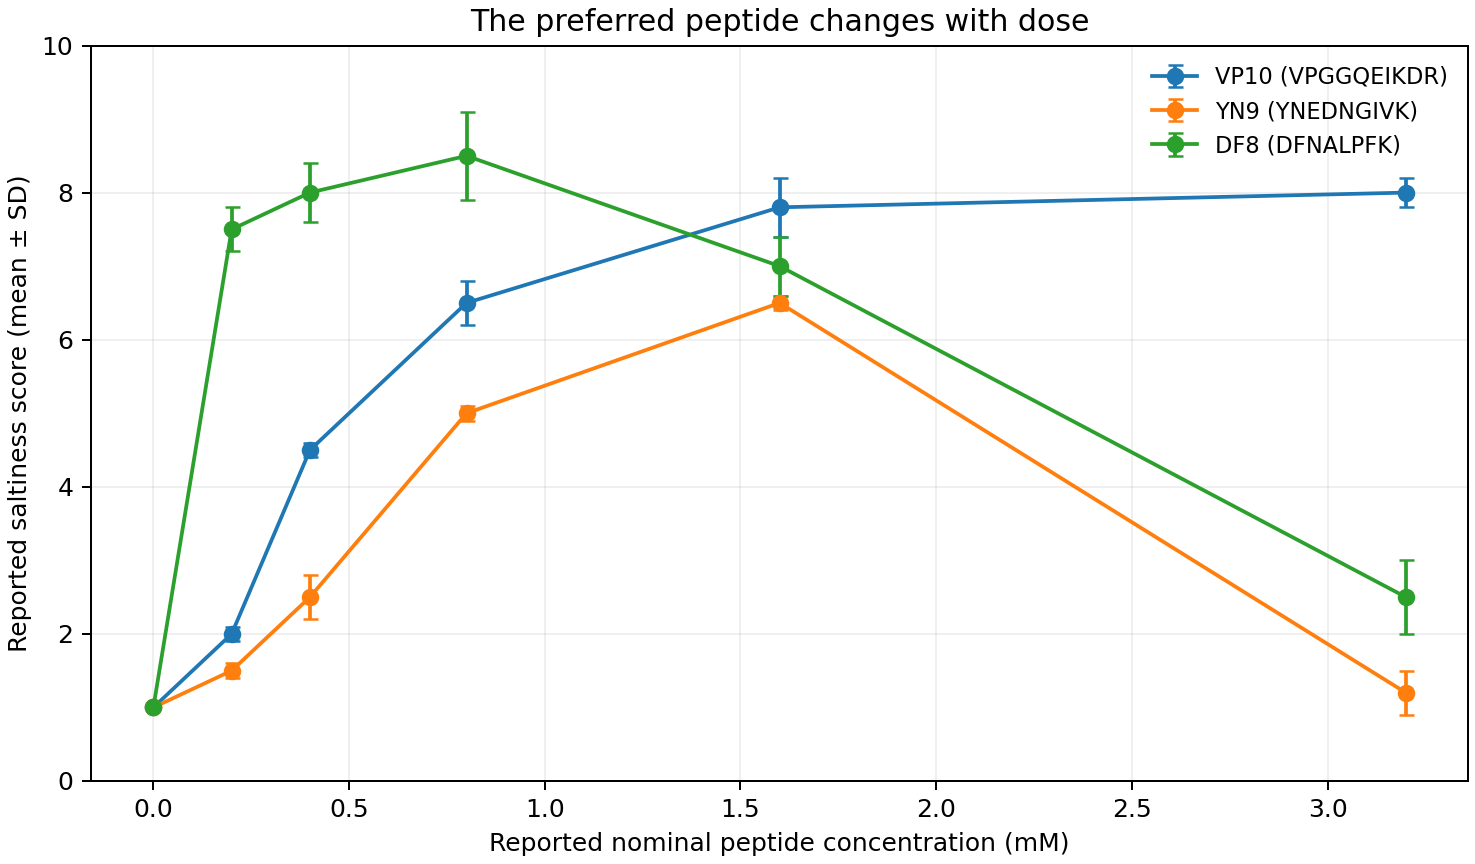

nominal_peptide_mM,ranked_aliases
0.2,DF8 > VP10 > YN9
0.4,DF8 > VP10 > YN9
0.8,DF8 > VP10 > YN9
1.6,VP10 > DF8 > YN9
3.2,VP10 > DF8 > YN9


sequence,alias,peak_nominal_mM,peak_mean,last_mean,peak_to_last_change,nondecreasing_means
DFNALPFK,DF8,0.8,8.5,2.5,-6.0,False
VPGGQEIKDR,VP10,3.2,8.0,8.0,0.0,True
YNEDNGIVK,YN9,1.6,6.5,1.2,-5.3,False


model,panel,n_candidates,reported_significant_total,reported_significant_in_top3,expected_retrieval_uniform_random,top3,score_ties,interpretation
length_only,october_mushroom_2026,5,3,2,1.8,FGDDP;GDDWT;LDDGF,True,Descriptive retrieval in selected panels; not general-population accuracy
length_only,pleurotus_2026,6,3,1,1.5,FSDY;SPTP;GYDTF,True,Descriptive retrieval in selected panels; not general-population accuracy
charge_length,october_mushroom_2026,5,3,2,1.8,FGDDP;GDDWT;LDDGF,True,Descriptive retrieval in selected panels; not general-population accuracy
charge_length,pleurotus_2026,6,3,1,1.5,AGHDDFP;EMMETPPGF;FSDY,False,Descriptive retrieval in selected panels; not general-population accuracy
composition_logistic,october_mushroom_2026,5,3,1,1.8,GDDWT;FGDDP;DDPRLP,False,Descriptive retrieval in selected panels; not general-population accuracy
composition_logistic,pleurotus_2026,6,3,1,1.5,AGHDDFP;SPTP;FSDY,False,Descriptive retrieval in selected panels; not general-population accuracy
extra_trees,october_mushroom_2026,5,3,2,1.8,DDPRLP;ASHGEGF;GDDWT,False,Descriptive retrieval in selected panels; not general-population accuracy
extra_trees,pleurotus_2026,6,3,1,1.5,SPTP;FSDY;AGHDDFP,False,Descriptive retrieval in selected panels; not general-population accuracy


In [4]:
display(Image(filename=str(RESULTS/'dose_rank_reversal.png')))
table('dose_rankings.csv')
table('dose_summary.csv')
print('Fixed-model retrieval of reported significant enhancers; random expectation is descriptive:')
table('panel_retrieval.csv')
print('Scores are not calibrated probabilities of NaCl enhancement.')

## Chemical consistency and the decision

Check all eight Figure S1 caption m/z values against the explicitly assumed unmodified, linear peptides and protonated charges 1–6. DFNALPFK has a large unresolved mismatch. Other deviations near 0.01 Da must not be treated as equivalent to that large discrepancy. This is **not** raw-spectrum re-identification or proof that synthesized material was incorrect.

The whole six-candidate Pleurotus panel is the more informative comparator set for a follow-up: three enhancers and three assay-specific non-significant candidates. First establish dose windows at explicitly final NaCl concentrations with peptide-only, NaCl-only, pH and counterion controls. Receptor mechanisms require functional perturbation evidence. These data do not yet justify a new virtual screen, a general dose-response ML model, or sodium-reduction claims.

In [5]:
table('caption_mass_check.csv')
print('All 44 fixed-model candidate scores:')
table('heldout_panel_scores.csv')
print('Detailed source interpretation and follow-up decision:')
print((WORK/'README.md').read_text())
EXPORT=BASE/'Saltiness_Assay_Conditions_Run.zip'
with zipfile.ZipFile(EXPORT,'w',zipfile.ZIP_DEFLATED) as z:
    for folder in [WORK,LOGS]:
        for p in sorted(folder.rglob('*')):
            if p.is_file() and '__pycache__' not in p.parts:
                z.write(p,p.relative_to(BASE))
print('Export:',EXPORT,'bytes:',EXPORT.stat().st_size)
display(FileLink(str(EXPORT)))
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(str(EXPORT))

All 44 fixed-model candidate scores:
Detailed source interpretation and follow-up decision:
# Saltiness enhancement depends on assay and dose

Research and analysis by **Ratchanon Preecha**, 15 October 2026.

**[Executed notebook](Saltiness_Assay_Conditions.ipynb)** · **[Run in Colab](https://colab.research.google.com/github/preecharatchanon-arch/Ratc/blob/main/projects/salt-casr/assay-conditions/Saltiness_Assay_Conditions.ipynb)** · [Protocol](PROTOCOL.md) · [Data](data) · [Every model score](results/heldout_panel_scores.csv)

The preceding [source-transfer experiment](../sensory-continuation) found that
sequence models did not transfer reliably between reference groups. This follow-up
asks a more specific question: **are the labels and rankings stable when the
endpoint, NaCl background and peptide dose are made explicit?**

This is retrospective analysis of published experiments. The experimental
discoveries belong to the cited authors. Our contributions are the cross-source
label ch

sequence,neutral_monoisotopic_mass,reported_mz,closest_protonated_charge,calculated_mz,difference_Da,matches_to_two_decimal_precision,mismatch_over_point1_Da,assumptions
DFNALPFK,950.4861675520001,574.25,2,476.25036024262107,97.99963975737893,False,True,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation
VPGGQEIKDR,1097.582921448,366.87,3,366.868250282621,0.0017497173790275156,True,False,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation
GVGPFDDDR,976.4250238400001,489.22,2,489.2197883866211,0.00021161337895136967,True,False,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation
SEHEENGYAV,1133.462531544,567.75,2,567.738542238621,0.011457761379006115,False,False,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation
YNEDNGIVK,1050.49818878,526.26,2,526.256370856621,0.003629143379043853,True,False,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation
IDNEPEFRWA,1275.5884007519996,638.81,2,638.8014768426208,0.008523157379158874,False,False,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation
DKLHEGIK,938.5185303000002,313.85,3,313.84678656662106,0.0032134333789599623,True,False,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation
IGDEAAENRN,1087.489414988,544.75,2,544.7519839606209,-0.0019839606209188787,True,False,Unmodified linear peptide; free termini; [M+zH]/z; z=1..6; not MS/MS validation


panel,sequence,doi,peptide_mg_mL,NaCl_mg_mL,outcome,standalone_descriptors,TI_Imax,TI_SD,TI_control_Imax,TI_control_SD,NaCl_calibration_mg_mL,calibration_scores,outcome_source,numeric_source,notes,model,score,rank_within_panel
october_mushroom_2026,FGDDP,10.1038/s41538-026-01088-9,1,3,unresolved_less_pronounced,umami; sourness,,,,,3;6;9,5;10;15,Results QDA; Table 1 descriptors,not transcribed,Two less-pronounced outcomes not relabelled inactive.,length_only,0.5067571524021197,1
october_mushroom_2026,GDDWT,10.1038/s41538-026-01088-9,1,3,significant_enhancement,umami; sourness,,,,,3;6;9,5;10;15,Results QDA; Table 1 descriptors,not transcribed,Two less-pronounced outcomes not relabelled inactive.,length_only,0.5067571524021197,2
october_mushroom_2026,LDDGF,10.1038/s41538-026-01088-9,1,3,significant_enhancement,umami; sourness; sweetness,,,,,3;6;9,5;10;15,Results QDA; Table 1 descriptors,not transcribed,Two less-pronounced outcomes not relabelled inactive.,length_only,0.5067571524021197,3
october_mushroom_2026,DDPRLP,10.1038/s41538-026-01088-9,1,3,unresolved_less_pronounced,umami; sourness; bitterness,,,,,3;6;9,5;10;15,Results QDA; Table 1 descriptors,not transcribed,Two less-pronounced outcomes not relabelled inactive.,length_only,0.5015911362070861,4
october_mushroom_2026,ASHGEGF,10.1038/s41538-026-01088-9,1,3,significant_enhancement,umami; sourness; saltiness,,,,,3;6;9,5;10;15,Results QDA; Table 1 descriptors,not transcribed,Two less-pronounced outcomes not relabelled inactive.,length_only,0.49642478027584847,5
pleurotus_2026,FSDY,10.1038/s41538-025-00681-8,1,3,not_significant_in_this_assay,umami; sour,,,5.5,0.32,3;5;7,5;10;15,Figure 1A; Results QDA,not transcribed,"Non-significance is assay-specific, not evidence of universal inactivity.",length_only,0.5119217260724256,1
pleurotus_2026,SPTP,10.1038/s41538-025-00681-8,1,3,not_significant_in_this_assay,umami; sour; bitter; astringent,,,5.5,0.32,3;5;7,5;10;15,Figure 1A; Results QDA,not transcribed,"Non-significance is assay-specific, not evidence of universal inactivity.",length_only,0.5119217260724256,2
pleurotus_2026,GYDTF,10.1038/s41538-025-00681-8,1,3,significant_enhancement,umami; sour,8.58,0.38,5.5,0.32,3;5;7,5;10;15,Figure 1A; Results QDA,"Supplement Table S2 (time-intensity, not Figure 1A bars)","Non-significance is assay-specific, not evidence of universal inactivity.",length_only,0.5067571524021197,3
pleurotus_2026,NGYDMR,10.1038/s41538-025-00681-8,1,3,significant_enhancement,umami; sour; sweet,7.25,0.27,5.5,0.32,3;5;7,5;10;15,Figure 1A; Results QDA,"Supplement Table S2 (time-intensity, not Figure 1A bars)","Non-significance is assay-specific, not evidence of universal inactivity.",length_only,0.5015911362070861,4
pleurotus_2026,AGHDDFP,10.1038/s41538-025-00681-8,1,3,significant_enhancement,umami; sour; salty; slight bitter,8.83,0.41,5.5,0.32,3;5;7,5;10;15,Figure 1A; Results QDA,"Supplement Table S2 (time-intensity, not Figure 1A bars)","Non-significance is assay-specific, not evidence of universal inactivity.",length_only,0.49642478027584847,5


/workspace/scratch/cadb742a5030/research/assay_conditions_20261015/notebook_validation/salt_assay_conditions/Saltiness_Assay_Conditions_Run.zip